Zdjęć: 4688 | Pacjentów: 2745
          zdjecia  pacjenci
cls                        
cataract      263       184
diabetes     1389       915
glaucoma      218       140
normal       2818      1816

Braki danych:
ID             0
Patient Age    0
Patient Sex    0
filename       0
dtype: int64
Zdjęcia bez pliku na dysku: 0

Dokładne duplikaty: 0
Empty DataFrame
Columns: [filename, ID, cls, md5]
Index: []

Rozmiary obrazów:
        width  height
count  4688.0  4688.0
mean   2453.0  1809.0
std     620.0   424.0
min     250.0   188.0
25%    2048.0  1632.0
50%    2592.0  1728.0
75%    2592.0  1944.0
max    5184.0  3456.0

Najczęstsze rozmiary:
2592x1728    1385
2048x1536     383
2304x1728     313
1956x1934     301
2736x1824     234
Name: count, dtype: int64

Średnia jasność per klasa:
cls
cataract    63.5
diabetes    53.9
glaucoma    46.8
normal      54.0
Name: brightness, dtype: float64


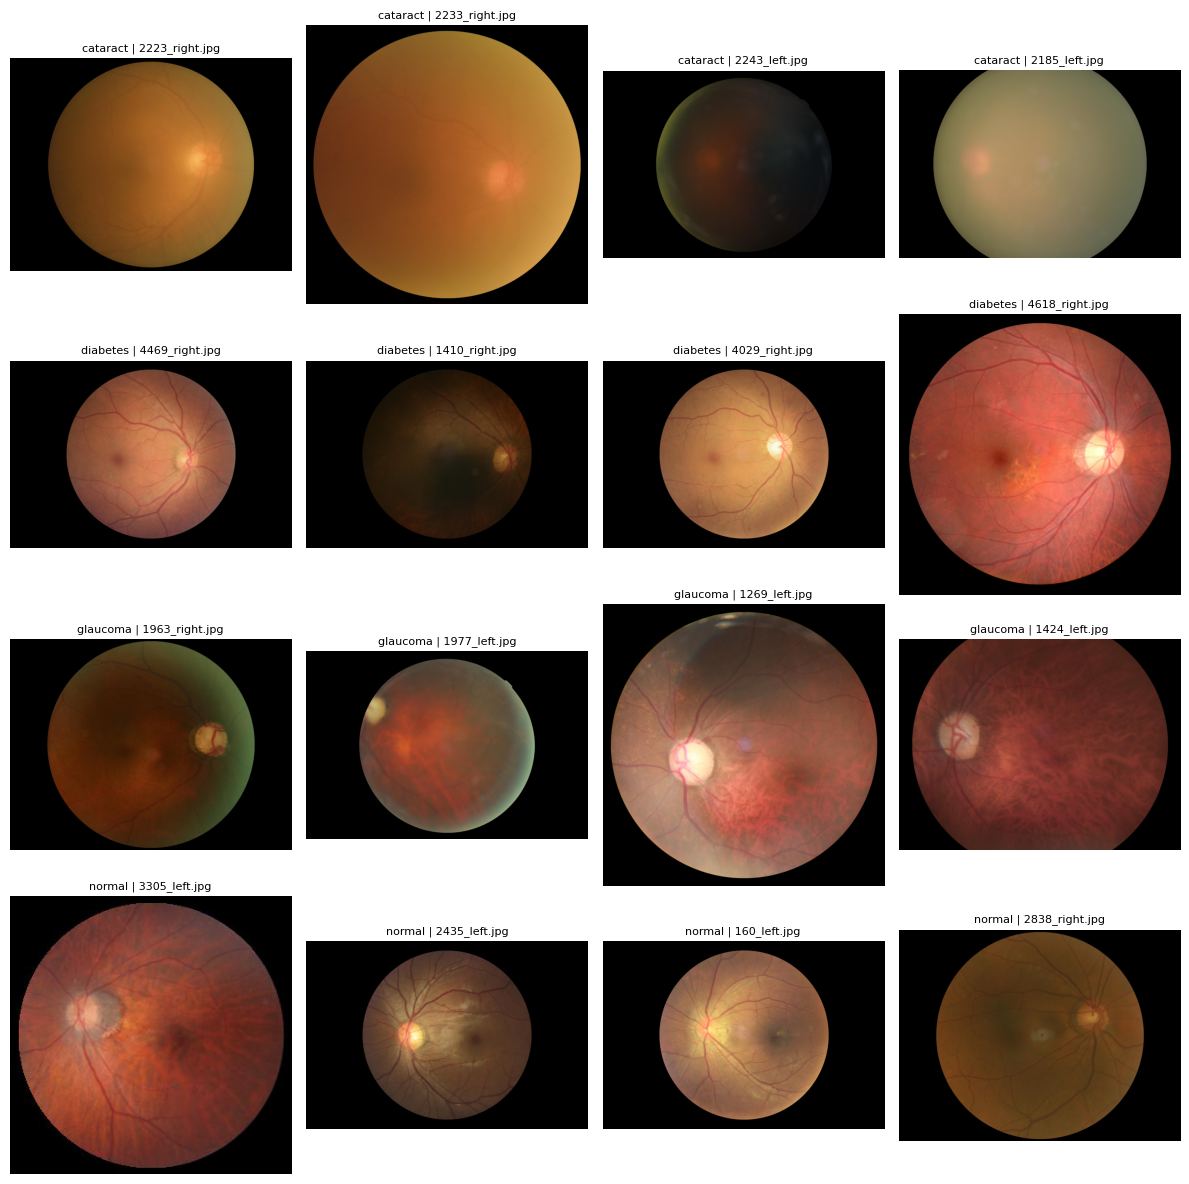

Pacjentów: 2745 | grup po scaleniu duplikatów: 2745
Kontrole wycieków: OK (brak wspólnych pacjentów, grup, plików i identycznych zdjęć)

     zbior  zdjecia  % zdjec  pacjenci  cataract zdj.  cataract pac.  diabetes zdj.  diabetes pac.  glaucoma zdj.  glaucoma pac.  normal zdj.  normal pac.
     train     3363     71.7      1961            190            135            996            660            156            100         2021         1298
validation      672     14.3       392             45             30            201            129             27             17          399          258
      test      653     13.9       392             28             19            192            126             35             23          398          260

Udział klas w każdym zbiorze (%), czyli czy stratyfikacja zadziałała:
          calosc  train  validation  test
cls                                      
cataract     5.6    5.6         6.7   4.3
diabetes    29.6   29.6        29.9  29.4
glau

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
 

from pathlib import Path
import kagglehub

# kagglehub.login()
 
DATA_DIR = Path(kagglehub.dataset_download("andrewmvd/ocular-disease-recognition-odir5k"))

import re
import pandas as pd
 
df = pd.read_csv(next(DATA_DIR.rglob("full_df.csv")))
 
def keywords_for_this_eye(row):
    if "left" in row["filename"].lower():
        return row["Left-Diagnostic Keywords"]
    return row["Right-Diagnostic Keywords"]
 
def map_kw(k):
    k = k.strip().lower()
    if k == "normal fundus":
        return "normal"
    if "hypertensi" in k:
        return None
    if "retinopathy" in k:
        return "diabetes"
    if "glaucoma" in k:
        return "glaucoma"
    if "cataract" in k:
        return "cataract"
    return None
 
def to_class(kw):
    parts = [p for p in re.split(r"[,，;；]", str(kw)) if p.strip()]
    classes = {map_kw(p) for p in parts}
    if len(classes) == 1 and None not in classes:
        return classes.pop()
    return None
 
df["kw"] = df.apply(keywords_for_this_eye, axis=1)
df["cls"] = df["kw"].apply(to_class)
res = df.dropna(subset=["cls"]).copy()
 
# ścieżki do zdjęć
paths = {p.name: p for p in DATA_DIR.rglob("*.jpg") if "Training Images" in str(p)}
res["path"] = res["filename"].map(paths)
 
import hashlib
from PIL import Image
 
# 1) liczba przykładów i rozkład klas
print("Zdjęć:", len(res), "| Pacjentów:", res["ID"].nunique())
print(res.groupby("cls").agg(zdjecia=("filename", "count"), pacjenci=("ID", "nunique")))
 
# 2) braki danych
print("\nBraki danych:")
print(df[["ID", "Patient Age", "Patient Sex", "filename"]].isna().sum())
print("Zdjęcia bez pliku na dysku:", res["path"].isna().sum())
 
# 3) wymiary, jasność, hash pliku (do duplikatów)
res = res.dropna(subset=["path"]).copy()
widths, heights, brightness, hashes = [], [], [], []
for p in res["path"]:
    img = Image.open(p)
    widths.append(img.width)
    heights.append(img.height)
    brightness.append(sum(img.convert("L").resize((64, 64)).getdata()) / 4096)
    hashes.append(hashlib.md5(Path(p).read_bytes()).hexdigest())
res["width"], res["height"], res["brightness"], res["md5"] = widths, heights, brightness, hashes
 
# 4) duplikaty
dups = res[res.duplicated("md5", keep=False)]
print("\nDokładne duplikaty:", len(dups))
print(dups.sort_values("md5")[["filename", "ID", "cls", "md5"]].head(20))
 
# 5) statystyki wejścia
print("\nRozmiary obrazów:")
print(res[["width", "height"]].describe().round(0))
print("\nNajczęstsze rozmiary:")
print((res["width"].astype(str) + "x" + res["height"].astype(str)).value_counts().head(5))
print("\nŚrednia jasność per klasa:")
print(res.groupby("cls")["brightness"].mean().round(1))
 
import matplotlib.pyplot as plt
 
classes = sorted(res["cls"].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes)))
for i, c in enumerate(classes):
    sample = res[res["cls"] == c].sample(4, random_state=42)
    for j, (_, row) in enumerate(sample.iterrows()):
        axes[i, j].imshow(Image.open(row["path"]))
        axes[i, j].set_title(f"{c} | {row['filename']}", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

##Podział

SEED = 42
 
parent = {i: i for i in res["ID"].unique()}
 
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
 
for _, g in res.groupby("md5"):
    ids = g["ID"].unique()
    for other in ids[1:]:
        parent[find(other)] = find(ids[0])
 
res["group_id"] = res["ID"].map(find)
print("Pacjentów:", res["ID"].nunique(), "| grup po scaleniu duplikatów:", res["group_id"].nunique())
 
def take_one_fold(data, n_splits):
    """Odcina jeden 'fold' (ok. 1/n_splits danych) tak, by grupy nie były rozdzielane."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    rest_idx, fold_idx = next(sgkf.split(data, data["cls"], groups=data["group_id"]))
    return data.iloc[rest_idx], data.iloc[fold_idx]
 
rest, test = take_one_fold(res, n_splits=7)      
train, val = take_one_fold(rest, n_splits=6)     
sets = {"train": train, "validation": val, "test": test}
 
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    A, B = sets[a], sets[b]
    assert set(A["group_id"]).isdisjoint(B["group_id"]), f"wspólne grupy: {a}/{b}"
    assert set(A["ID"]).isdisjoint(B["ID"]), f"wspólni pacjenci: {a}/{b}"
    assert set(A["filename"]).isdisjoint(B["filename"]), f"wspólne pliki: {a}/{b}"
    assert set(A["md5"]).isdisjoint(B["md5"]), f"identyczne zdjęcia: {a}/{b}"
print("Kontrole wycieków: OK (brak wspólnych pacjentów, grup, plików i identycznych zdjęć)\n")
 
classes = sorted(res["cls"].unique())
rows = []
for name, d in sets.items():
    row = {"zbior": name, "zdjecia": len(d), "% zdjec": round(100 * len(d) / len(res), 1),
           "pacjenci": d["ID"].nunique()}
    for c in classes:
        row[f"{c} zdj."] = int((d["cls"] == c).sum())
        row[f"{c} pac."] = int(d.loc[d["cls"] == c, "ID"].nunique())
    rows.append(row)
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
 
print("\nUdział klas w każdym zbiorze (%), czyli czy stratyfikacja zadziałała:")
shares = {"calosc": res}
shares.update(sets)
print(pd.DataFrame({n: (100 * d["cls"].value_counts(normalize=True)).round(1)
                    for n, d in shares.items()}).to_string())
 
SPLITS_DIR = Path("splits")      
SPLITS_DIR.mkdir(exist_ok=True)
 
for name, d in sets.items():
    out = (d[["filename", "group_id", "cls"]]
           .rename(columns={"filename": "id", "cls": "label"})
           .sort_values("id"))
    out.to_csv(SPLITS_DIR / f"{name}_ids.csv", index=False)
    print(f"{name}_ids.csv: {len(out)} wierszy")
 
back = {n: pd.read_csv(SPLITS_DIR / f"{n}_ids.csv") for n in sets}
assert sum(len(v) for v in back.values()) == len(res)
assert set().union(*[set(v["id"]) for v in back.values()]) == set(res["filename"])
print("Pliki zapisane poprawnie.")